# Lab 15: How to run model-written code safely

## Goal

Let an agent answer a data question with a chart by writing its own Python, and run that Python only where it cannot
reach your files. The moment that teaches it is one probe: a few lines **we** wrote that ask what any untrusted code
could ask. Is the `.env` file with your API key two folders up? Is the key in my environment? Can I reach the
internet? From a subprocess with a timeout, its own working folder and a trimmed environment, the probe finds the
`.env` file (`.env there: True`) and reaches the network. From a Docker container with no network, a read-only root and one
mounted folder, it finds neither. In OpenAI's hosted code interpreter it runs on another machine, where neither
exists. Then the agent draws the chart, and its code shows that the numbers took a path through the model: it typed
the five yearly totals into its code by hand (all five, in 3 of 3 runs).

## What you will learn

- What a subprocess with a timeout, a working folder and a trimmed environment stops, and what it does not, read
  from a probe we wrote.
- How to run code in a Docker container with limits (no network, a read-only root, memory, CPU, a process count, a
  user who is not root, one mounted folder), flag by flag.
- How to run code in OpenAI's hosted code interpreter with the Responses API, check that the code that ran is the code
  you sent, and price a run.
- How to give a chart agent a `run_python` tool that runs code only in a container or in the hosted sandbox, and
  refuses when neither is there.
- How to check a chart's numbers against the database, and why numbers the model typed are a risk even when they are
  right.
- Which isolation each option gives (a process, a container, a micro-VM, a hosted sandbox), and which products offer
  each.

## Where this lab starts

- Labs 03 and 04 wrote tool calling and the agent loop by hand on Chat Completions: the model sends a tool name and
  its arguments as JSON text, and our code decides whether anything runs. This lab uses the same loop, in one
  function.
- Lab 13 gave an agent a free `run_sql` tool on a database opened read-only, so a write fails whatever the model
  sends. The chart agent here gets the same tool.
- Lab 14's coding agent ran its tests, which run the code the model edited, on our machine with our permissions. Here
  the model writes the whole program, so where that program runs is the question.

This lab defines everything it uses, so it runs on its own.

**Model-written code never runs on your machine in this lab.** The agent's `run_python` tool sends code to a Docker
container when Docker is running, or to OpenAI's hosted code interpreter otherwise, and refuses when neither is
available. The only code that runs in a plain subprocess is the probe in Part B, which we wrote ourselves, to show
why a subprocess is not a sandbox.

## Setup

The first cell is the config cell every lab starts with (lab 00 explains it line by line): it finds the repository
folder by `models.env`, reads the model and the prices, and checks that the key is set without printing it. The
imports above it are the ones this lab needs.

In [1]:
from pathlib import Path
import base64
import difflib
import json
import os
import re
import shutil
import sqlite3
import subprocess
import sys
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The second cell sets up the rest: the OpenAI client, the lab's `outputs/` folder (git ignores it; every file this
notebook writes goes there), the shop's database opened read-only, and the prices. `price()` turns a call's token
counts into dollars: ordinary input, input read from the prompt cache, input written to the cache and output each
have their own price in `models.env`. The hosted sandbox in Part D also charges per container session; that price is
not a token price, so `models.env` keeps it on a line of its own, `PRICE_CONTAINER_SESSION_USD`.

In [2]:
from IPython.display import Image, display
from openai import OpenAI, omit

client = OpenAI()
LAB = ROOT / "15_Code_Execution"
OUTPUTS = LAB / "outputs"          # everything this notebook writes; git ignores this folder
OUTPUTS.mkdir(exist_ok=True)

# The shop's database, opened read-only: no query can change it
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)

# Prices in US dollars per token, from models.env
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"]) / 1e6
PRICE_CACHED = float(settings["PRICE_CACHED_INPUT_PER_MILLION"]) / 1e6
PRICE_WRITE = float(settings["PRICE_CACHE_WRITE_PER_MILLION"]) / 1e6
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"]) / 1e6
CONTAINER_SESSION_USD = float(settings["PRICE_CONTAINER_SESSION_USD"])  # one hosted 1 GB container, per 20-minute session


def price(input_tokens, cached, written, output_tokens):
    """Dollars for one call: ordinary input, cached input, cache writes and output, each at its own price."""
    ordinary = input_tokens - cached - written
    return ordinary * PRICE_IN + cached * PRICE_CACHED + written * PRICE_WRITE + output_tokens * PRICE_OUT


print("lab folder:", LAB.relative_to(ROOT), "| outputs:", OUTPUTS.relative_to(ROOT))
print("invoices in the database:", conn.execute("SELECT COUNT(*) FROM invoices").fetchone()[0])

lab folder: 15_Code_Execution | outputs: 15_Code_Execution/outputs
invoices in the database: 412


The database holds 412 invoices, and the notebook writes only inside `15_Code_Execution/outputs/`.

---

## Part A: Draw the reference chart from the database

Before any agent draws a chart, we draw it ourselves, so we know what the right chart looks like and which numbers it
must show. Everything in this part is our own code, running in this notebook.

The question is *the shop's revenue by year*. Each row of the `invoices` table is one sale, with its date in
`InvoiceDate` and its amount in `Total`. The query takes the year out of the date, adds up the totals per year and
rounds them to cents:

- `strftime('%Y', InvoiceDate)` reads the date and keeps only the year, as text (`'2009'`);
- `SUM(Total)` adds the invoice totals of each group, and `ROUND(..., 2)` rounds the sum to cents;
- `GROUP BY year` makes one group, and so one row, per year.

In [3]:
YEARLY_SQL = """
SELECT strftime('%Y', InvoiceDate) AS year, ROUND(SUM(Total), 2) AS revenue
FROM invoices
GROUP BY year
ORDER BY year
"""
rows = conn.execute(YEARLY_SQL).fetchall()
print(rows)

[('2009', 449.46), ('2010', 481.45), ('2011', 469.58), ('2012', 477.53), ('2013', 450.58)]


A list of 5 tuples, one per year from 2009 to 2013. In each tuple the first item is
the year as text and the second is that year's revenue in US dollars. We keep them in a dictionary, year to revenue,
because later parts look a year's revenue up by its year: `dict(rows)` turns each `(key, value)` pair into one entry.

In [4]:
TRUTH = dict(rows)
print(TRUTH)

{'2009': 449.46, '2010': 481.45, '2011': 469.58, '2012': 477.53, '2013': 450.58}


These five numbers are what any chart of this question must show. Now the chart itself, drawn by our code with
matplotlib: one bar per year, saved to `outputs/reference_chart.png`.

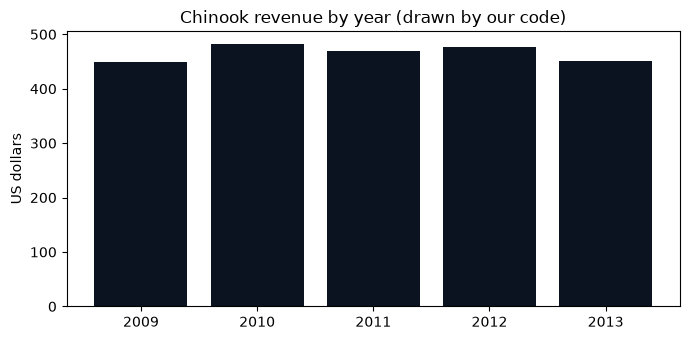

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(list(TRUTH), list(TRUTH.values()), color="#0B1220")
ax.set_title("Chinook revenue by year (drawn by our code)")
ax.set_ylabel("US dollars")
fig.tight_layout()
fig.savefig(OUTPUTS / "reference_chart.png")
plt.show()

Five bars of nearly the same height: the highest year is 2010 with $481.45, the lowest 2009 with
$449.46, about $32 apart. So a chart can look right and still be wrong: one mistyped digit in one bar
would hardly show. Keep this chart and these numbers in mind for Part F.

**Checkpoint A.** Five rows, from 2009 ($449.46) to 2013 ($450.58), with 2010 the highest ($481.45), and the
reference chart in `outputs/reference_chart.png`.

---

## Part B: Test what a subprocess can reach with a probe

When a model writes code, our code has to run it somewhere. The first idea most of us have is a new Python process
with a few controls: a timeout, its own working folder, and only the environment variables it needs. Before we trust
that, we test it. Not with model-written code: with a **probe**, a few lines we wrote ourselves that ask the
questions any untrusted code could ask.

⚠️ **This part runs only the fixed text below in a subprocess.** No code a model wrote ever runs this way, in this
lab or in anything you build: Part E's `run_python` has no branch that could do it.

### The probe

Each line asks one question, and prints a fact, never the contents of a file:

1. **`working folder:`** the name of the folder the code starts in (`Path.cwd()`; `.name` keeps only the last part
   of the path).
2. **`two folders up:`** where `../..` leads. `.resolve()` turns the relative path into a real one; its `.name` is
   the folder's name, or empty at the top of the disk, which we print as `/`.
3. **`.env there:`** whether a file called `.env` exists two folders up. In your copy of this repository that is the
   file that holds your API key.
4. **`key in environment:`** whether the variable `OPENAI_API_KEY` was passed to the process.
5. **`network:`** whether a connection to `pypi.org` on port 443 (the HTTPS port) opens within 3 seconds.
   `socket.create_connection` opens one, and raises an `OSError` when it cannot; we print the error's type.

In [6]:
PROBE = """import os, pathlib, socket
print("working folder:", pathlib.Path.cwd().name)
print("two folders up:", pathlib.Path("../..").resolve().name or "/")
print(".env there:", pathlib.Path("../../.env").exists())
print("key in environment:", "OPENAI_API_KEY" in os.environ)
try:
    socket.create_connection(("pypi.org", 443), timeout=3).close()
    print("network: reachable")
except OSError as error:
    print("network: blocked,", type(error).__name__)
"""
(OUTPUTS / "probe.py").write_text(PROBE)
print("probe written:", (OUTPUTS / "probe.py").relative_to(ROOT))

probe written: 15_Code_Execution/outputs/probe.py


First, what this notebook itself can see. It is our own code, so it may read anything: the `.env` file sits in the
repository folder, and the config cell put the key in this process's environment.

In [7]:
print(".env in the repository folder:", (ROOT / ".env").exists())
print("key in this notebook's environment:", "OPENAI_API_KEY" in os.environ)

.env in the repository folder: True
key in this notebook's environment: True


Both `True`. Now the subprocess, with three controls. `subprocess.run` starts a new program and waits for it:

- `[sys.executable, "probe.py"]` is the program and its argument: the same Python this notebook runs on, and our
  probe file;
- `cwd=OUTPUTS` is the first control: the process starts in `15_Code_Execution/outputs/`, so its relative paths
  begin there;
- `env={"PATH": ...}` is the second: the process gets only the `PATH` variable, so the API key in our environment is
  not passed on;
- `timeout=10` is the third: Python stops the process after 10 seconds;
- `capture_output=True, text=True` collects what the process prints as text, in `result.stdout`.

Before you run it: which of the five lines will the controls change?

In [8]:
result = subprocess.run(
    [sys.executable, "probe.py"],
    cwd=OUTPUTS,
    env={"PATH": os.environ["PATH"]},
    timeout=10,
    capture_output=True, text=True,
)
print(result.stdout)

working folder: outputs
two folders up: ai_agents_course
.env there: True
key in environment: False
network: reachable



Read it line by line:

- **working folder: outputs**, as we set: the working folder control did its job.
- **two folders up: ai_agents_course**: from `outputs/`, `../..` is the repository folder. A working folder is where
  relative paths *start*; `..` climbs out of it, as far as the disk allows.
- **.env there: True**: the file with the key is right there. Reading it would be one more line, `open(...).read()`.
- **key in environment: False**: the trimmed environment did its job, and it did not matter, because the same key
  is in a file the process can open.
- **network: reachable**: nothing stops the process from sending what it read to any address.

**A timeout and a working folder are not a sandbox.** They limit how long code runs and where its relative paths
start; they do not limit what it can see or where it can send it.

The timeout is the one control left to try. A program that never ends, `while True: pass`, shows what it stops.
`subprocess.TimeoutExpired` is the error `subprocess.run` raises when the time is up (after it has stopped the
process); we catch it and print its name and the limit.

In [9]:
(OUTPUTS / "forever.py").write_text("while True:\n    pass\n")
try:
    subprocess.run([sys.executable, "forever.py"], cwd=OUTPUTS, env={"PATH": os.environ["PATH"]}, timeout=3)
except subprocess.TimeoutExpired as error:
    print(type(error).__name__, "after", error.timeout, "seconds: the process was stopped")

TimeoutExpired after 3 seconds: the process was stopped


Stopped after 3 seconds. So the timeout works, for what it is: it stops code that runs too long, not code that does
harm in the first second.

Here are the four sandbox controls, with what our subprocess had and what each one stops:

| Control | Does our subprocess have it? | What it stops | What the probe showed |
|---|---|---|---|
| A timeout | yes, `timeout=10` | code that runs forever | `forever.py` stopped after 3 s |
| A working folder | yes, `cwd=OUTPUTS` | stray writes with relative paths landing next to your files | `working folder: outputs`, and still `../..` climbed to the repository |
| No network | no | sending data out | `network: reachable` |
| Only one folder mounted | no | seeing the rest of the disk at all | `.env there: True` |

The trimmed environment is a fifth, smaller control: it kept the key out of the process's variables
(`key in environment: False`), and the key was still one file away. The two controls our subprocess lacks are the
two that would have changed the probe's answers, and a plain process cannot have them. A container can.

**Checkpoint B.** `.env there: True`, `key in environment: False`, `network: reachable` from the subprocess, and
`TimeoutExpired after 3 seconds` for the endless loop.

---

## Part C: Run code in a container with limits

A **container** is a process that runs with its own filesystem, built from an **image** (a packaged copy of an
operating system's files plus what we install), its own network settings and its own limits. It sees a folder of
ours only when we **mount** it. That gives us the two missing controls: no network, and one folder visible.

Docker is optional for this lab. The next cell asks the Docker service (the daemon) for its version; it answers only
when Docker is installed and running. Without it, every container cell prints a skip line, and `run_python` in Part E
uses the hosted sandbox instead.

In [10]:
DOCKER_OK = False
if shutil.which("docker") is None:
    print("docker: not installed. The container cells will skip; run_python will use the hosted sandbox.")
else:
    info = subprocess.run(["docker", "info", "--format", "{{.ServerVersion}}"], capture_output=True, text=True)
    DOCKER_OK = info.returncode == 0
    print("docker server:", info.stdout.strip() if DOCKER_OK else info.stderr.strip()[:200])
SKIP = "Docker is not available: skipped. The saved output shows our run."

docker server: 29.9.1


Our Docker server is version 29.9.1.

### The image, line by line

The image is described by `resources/Dockerfile`, a short recipe Docker follows from top to bottom:

In [11]:
print((LAB / "resources" / "Dockerfile").read_text())

# The sandbox image for lab 15's container runner.
# Build it from the repository folder:  docker build -t chinook-sandbox 15_Code_Execution/resources
FROM python:3.13.18-slim

# The one library the chart code needs, pinned to the version the repository uses
RUN pip install --no-cache-dir matplotlib==3.11.2

# An ordinary user with no special rights; code in the container runs as this user, never as root
RUN useradd --create-home --uid 1000 sandbox
USER sandbox

# Matplotlib keeps a small cache; /tmp is the only writable place besides the mounted folder
ENV MPLCONFIGDIR=/tmp/matplotlib
WORKDIR /work



- **`FROM python:3.13.18-slim`** starts from the official Python image: a small Debian Linux with Python 3.13.18. We
  name the exact patch release, so every build gets the same Python.
- **`RUN pip install --no-cache-dir matplotlib==3.11.2`** adds the one library chart code needs, at the version this
  repository pins (numpy comes with it). Nothing else is installed: no database driver, no `requests`.
- **`RUN useradd --create-home --uid 1000 sandbox`** and **`USER sandbox`** create an ordinary user and make it the
  user every command runs as. Inside the container, code is not root, so it cannot change the image's system files
  even if the root filesystem were writable.
- **`ENV MPLCONFIGDIR=/tmp/matplotlib`** tells matplotlib where to keep the small cache it writes when it starts. We
  will make the root read-only, so `/tmp` is the only writable place besides the mounted folder.
- **`WORKDIR /work`** is the folder code starts in, and where we will mount our `outputs/` folder.

`docker build --tag chinook-sandbox resources/` turns the recipe into an image named `chinook-sandbox`. The first
build downloads the Python image and installs matplotlib, which needs the internet and takes a minute or two; later
builds reuse every step from Docker's cache and finish at once. `--quiet` prints only the image's id. Then we start
one throwaway container from the image to read what it holds.

In [12]:
if DOCKER_OK:
    build = subprocess.run(["docker", "build", "--quiet", "--tag", "chinook-sandbox", str(LAB / "resources")],
                           capture_output=True, text=True)
    print("built:", build.returncode == 0, "|", (build.stdout or build.stderr).strip()[:80])
    inside = ("import sys, getpass, matplotlib; "
              "print('python', sys.version.split()[0], '| matplotlib', matplotlib.__version__, '| user', getpass.getuser())")
    check = subprocess.run(["docker", "run", "--rm", "chinook-sandbox", "python", "-c", inside], capture_output=True, text=True)
    print(check.stdout.strip())
else:
    print(SKIP)

built: True | sha256:56d94255c7c3e7045fad945f31ac575029442577e839d6483199b7295f80fd59


python 3.13.18 | matplotlib 3.11.2 | user sandbox


The image is built, and inside it Python 3.13.18 runs with matplotlib 3.11.2 as the user `sandbox`: the
three things the Dockerfile asked for. The long `sha256:` string is the image's id, a fingerprint of its contents.

### The limits, flag by flag

`docker run` starts a container from an image. Everything between `run` and the image name is a flag that sets one
limit. We keep them in a list so every run uses the same ones:

In [13]:
SANDBOX_FLAGS = [
    "--rm",                                         # delete the container when the code ends
    "--network", "none",                            # no network at all
    "--read-only",                                  # the image's own files cannot be changed
    "--tmpfs", "/tmp",                              # ... except an empty /tmp, kept in memory
    "--memory", "256m", "--memory-swap", "256m",    # 256 MB of memory, and no swap on top of it
    "--cpus", "1",                                  # at most one CPU
    "--pids-limit", "64",                           # at most 64 processes, so code cannot start them without end
    "--cap-drop", "ALL",                            # none of the special powers Linux gives root
    "--security-opt", "no-new-privileges",          # no way to gain more rights while it runs
]
MOUNT = ["--volume", f"{OUTPUTS}:/work"]           # our outputs folder appears as /work; nothing else of ours does
OUTPUTS.chmod(0o777)                                # the container's user is not you: let it write in this one folder
print(len(SANDBOX_FLAGS), "flag values, one folder mounted at /work")

18 flag values, one folder mounted at /work


The print counts the list's items: 18, because most flags are followed by their value as a separate item
(`"--memory", "256m"`). Two lines need a word more:

- `MOUNT` is the **only folder mounted**: `--volume HOST:CONTAINER` makes our `outputs/` folder appear inside the
  container as `/work`, the working folder. Code there can read and write that folder, and that is all of our disk it
  can see.
- `OUTPUTS.chmod(0o777)` lets any user write in `outputs/`. The container's user `sandbox` has a different user id
  from yours on some machines, and the folder holds only what this notebook writes.

The command ends with the image and the program to run inside it: `timeout 20 python probe.py`. `timeout` is a small
program in the image that stops `python` after 20 seconds; the container ends with it, and `--rm` deletes it. That
is the timeout control, inside the container. Now the same probe, in the container:

In [14]:
if DOCKER_OK:
    result = subprocess.run(["docker", "run", *SANDBOX_FLAGS, *MOUNT, "chinook-sandbox", "timeout", "20", "python", "probe.py"],
                            capture_output=True, text=True)
    print(result.stdout, result.stderr)
else:
    print(SKIP)

working folder: work
two folders up: /
.env there: False
key in environment: False
network: blocked, gaierror
 


The same five lines, other answers:

- **working folder: work**: the probe started in `/work`, which is our `outputs/` folder.
- **two folders up: /**: inside the container, `../..` from `/work` is the top of the container's own disk. Our
  repository is not there to climb to.
- **.env there: False** and **key in environment: False**: the file does not exist in the container's world, and
  Docker passes no variables of ours unless we ask.
- **network: blocked, gaierror**: `gaierror` means the name `pypi.org` could not even be looked up. With
  `--network none` the container has no network card besides its own loopback.

What does `False` establish? That this code, in this container, cannot see our files or reach the network. It does
not make the container a perfect wall: every container shares your machine's operating system kernel, and a flaw in
the kernel can let code out. Part G comes back to that.

### Wrap the command in a function

The command works on one probe. The agent will send code many times, so we put the same steps into one function:
write the code to `outputs/run.py` (which is `/work/run.py` inside), run it in a fresh container with the same flags,
and return what it printed (the last 2,000 characters, so a long error does not flood the model). When the code
prints nothing, it says so with the exit code.

In [15]:
def run_in_container(code):
    """Run Python code in the sandbox container; return what it printed."""
    (OUTPUTS / "run.py").write_text(code)
    result = subprocess.run(
        ["docker", "run", *SANDBOX_FLAGS, *MOUNT, "chinook-sandbox", "timeout", "20", "python", "run.py"],
        capture_output=True, text=True,
    )
    printed = result.stdout + result.stderr
    return printed[-2000:] if printed else f"finished with exit code {result.returncode}, printed nothing"

Two small tests: an ordinary calculation, and a write to the container's own disk outside `/work`, in the sandbox
user's home folder (`Path.home()`), which `--read-only` should refuse. The second program catches the error and prints
its message (`error.strerror`), the operating system's reason in words.

In [16]:
if DOCKER_OK:
    print(run_in_container("print(sum(range(10)))").strip())
    write_home = ("from pathlib import Path\n"
                  "try:\n"
                  "    (Path.home() / 'note.txt').write_text('hello')\n"
                  "    print('written')\n"
                  "except OSError as error:\n"
                  "    print('refused:', error.strerror)\n")
    print(run_in_container(write_home).strip())
else:
    print(SKIP)

45


refused: Read-only file system


The calculation prints `45`, and the write is `refused: Read-only file system`: even the sandbox user's own home folder is part
of the read-only root. Only `/work` and `/tmp` can be written.

**Checkpoint C.** Docker's version (or the skip line); the image built with Python 3.13.18, matplotlib 3.11.2 and the
user `sandbox`; the probe in the container prints `.env there: False`, `key in environment: False` and
`network: blocked`; `run_in_container` returns `45` and a read-only error.

---

## Part D: Run code in a hosted sandbox

Docker is optional, and a container shares your machine's kernel. A **hosted sandbox** moves the code to someone
else's machine, made for this job. OpenAI's **code interpreter** is a tool of the Responses API: the model writes
Python, the API runs it in a container on OpenAI's side, and the response carries back the code that ran and what it
printed. It needs nothing but the API key you already have.

The tool takes a `container` setting. `"type": "auto"` asks the API to start a new container for the call;
`"memory_limit": "1g"` picks the smallest size (1 GB of memory); `"network_policy": {"type": "disabled"}` turns off
outbound network, which is the default, written out so we can see it.

The code interpreter is built for the model to write its *own* code. To run *our* code there, we tell the model to run
the text we send exactly as written, and afterwards we check that it did. `tool_choice="required"` makes the model call
the tool instead of answering from memory, and `include=["code_interpreter_call.outputs"]` asks the API to send back
what the code printed.

⚠️ **This cell costs money:** one container session ($0.03 for 1 GB, per 20-minute session, on OpenAI's pricing page
on 30 Oct 2026) plus the model's tokens.

In [17]:
HOSTED_CONTAINER = {"type": "auto", "memory_limit": "1g", "network_policy": {"type": "disabled"}}
RUN_AS_WRITTEN = ("Run the user's Python code with the python tool exactly as written, once, without changing it. "
                  "Then reply with what it printed.")

response = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    instructions=RUN_AS_WRITTEN,
    input=PROBE,
    tools=[{"type": "code_interpreter", "container": HOSTED_CONTAINER}],
    tool_choice="required",
    include=["code_interpreter_call.outputs"],
)
print([item.type for item in response.output])

['code_interpreter_call', 'message']


The response's `output` is a list of items, in the order they happened: `code_interpreter_call`, then `message`. The first is the tool call the
model made; the last is the model's short reply. The call is the item we read. `next(...)` walks the list and returns
the first item that matches, here the one whose `type` is `code_interpreter_call`. It has three fields we need:

- `container_id`: the container the API started for this call;
- `code`: the code that actually ran, as the model wrote it;
- `outputs`: what the code produced, here one `logs` entry with the printed text.

In [18]:
call = next(item for item in response.output if item.type == "code_interpreter_call")
print("container:", call.container_id[:16] + "...")
print("the code that ran is the code we sent:", call.code == PROBE)
print(call.outputs[0].logs)

container: cntr_6ae46940f10...
the code that ran is the code we sent: True
working folder: oai
two folders up: /
.env there: False
key in environment: False
network: blocked, gaierror



The code that ran is the code we sent (`True`), and it printed:

- **working folder: oai**, a folder on OpenAI's machine;
- **two folders up: /**, the top of that machine's disk;
- **.env there: False** and **key in environment: False**: our `.env` file is not hidden here, it is simply on
  another computer. The key we used to call the API never reaches the container;
- **network: blocked, gaierror**, as the network policy said.

What it cost: the model read our instructions and the probe and wrote the probe back as a tool call, and the
container session is billed on top of the tokens.

In [19]:
usage = response.usage
cached = usage.input_tokens_details.cached_tokens or 0
written = usage.input_tokens_details.cache_write_tokens or 0
tokens_usd = price(usage.input_tokens, cached, written, usage.output_tokens)
print("input tokens:", usage.input_tokens, "| output tokens:", usage.output_tokens)
print(f"tokens ${tokens_usd:.5f} + container session ${CONTAINER_SESSION_USD:.2f} = ${tokens_usd + CONTAINER_SESSION_USD:.4f}")

input tokens: 1515 | output tokens: 151
tokens $0.00012 + container session $0.03 = $0.0301


1,515 input tokens and 151 output tokens cost $0.00012. That is more input than our short
instructions and probe: the code interpreter adds its own instructions to every call. The container session costs
$0.03, about 250 times as much as the tokens. For a hosted sandbox the session, not the model, is most of the bill, so one session per
run of code matters when an agent runs code often.

### Wrap the call in a function

As with the container, the agent needs a function: send the code, read the call item, collect what it printed, and
save any chart. The code interpreter returns a chart as an `image` output whose `url` is a **data URL**: the text
`data:image/png;base64,` followed by the PNG file written as base64 text. `split(",", 1)[1]` keeps the part after the
first comma, and `base64.b64decode` turns it back into the PNG's bytes.

The function also compares the code that ran with the code we sent (`.strip()` ignores spaces and newlines at either
end). The model retypes our code to run it, so the two can differ; when they do, the result starts with a warning.
`hosted_runs` keeps both versions and the usage of every run, for the comparison below and the cost at the end.

In [20]:
hosted_runs = []     # every hosted run: the code we sent, the code that ran, and the usage


def run_hosted(code):
    """Run Python code in OpenAI's hosted code interpreter; return what it printed."""
    response = client.responses.create(
        model=MODEL,
        reasoning={"effort": EFFORT or omit},
        instructions=RUN_AS_WRITTEN,
        input=code,
        tools=[{"type": "code_interpreter", "container": HOSTED_CONTAINER}],
        tool_choice="required",
        include=["code_interpreter_call.outputs"],
    )
    call = next(item for item in response.output if item.type == "code_interpreter_call")
    hosted_runs.append({"sent": code, "ran": call.code, "usage": response.usage})
    printed, charts = "", 0
    for output in call.outputs or []:
        if output.type == "logs":
            printed += output.logs
        if output.type == "image":            # a chart comes back as a PNG inside a data URL
            charts += 1
            png = base64.b64decode(output.url.split(",", 1)[1])
            (OUTPUTS / f"hosted_chart_{charts}.png").write_bytes(png)
    if call.code.strip() != code.strip():
        printed = "Warning: the hosted runner changed the code before running it.\n" + printed
    return printed + (f"[{charts} chart(s) saved]" if charts else "")

### Why the runner compares the code that ran

Here is the same probe written another way, with `from pathlib import Path` on its second line. It asks the same
questions. Watch the first line of the result, and the lines `difflib.unified_diff` prints: it lists the lines that
differ between two texts, `-` for the line we sent and `+` for the line that ran, and prints nothing when they match.

In [21]:
PROBE_FROM_IMPORT = PROBE.replace("import os, pathlib, socket", "import os, socket\nfrom pathlib import Path").replace("pathlib.Path", "Path")
print(run_hosted(PROBE_FROM_IMPORT))
sent, ran = hosted_runs[-1]["sent"], hosted_runs[-1]["ran"]
for line in difflib.unified_diff(sent.splitlines(), ran.splitlines(), "sent", "ran", lineterm="", n=0):
    print(line)


--- sent
+++ ran
@@ -2 +2 @@
-from pathlib import Path
+from pathlib import import Path


The model changed the code before running it. Line 2 reached the hosted container as `from pathlib import import Path`, a line that is not valid Python, so the code stopped before it printed anything, and the result holds only our warning. The probe we sent was correct; the mistake came in on the way. This is why `run_hosted` compares the two texts: with a hosted code interpreter, the code you send is a request to the model, and `code_interpreter_call.code` is what actually ran. When the warning appears, read the difference before you trust the output.

**Checkpoint D.** The probe in the hosted sandbox prints `working folder: oai`, `.env there: False`,
`key in environment: False` and `network: blocked`; the code that ran is the code we sent; one run costs about
$0.03 for the session plus a fraction of a cent in tokens. The second probe shows whether the model retyped the code
faithfully (ours: changed, `from pathlib import import Path` on line 2).

---

## Part E: Give the chart agent a run_python tool that only runs in a sandbox

We now have two runners that keep code away from our files: the container and the hosted sandbox. The agent gets two
tools: `run_sql` to read the shop's database, and `run_python` to run the code it writes. Our code, not the model,
decides where `run_python` sends that code. The diagram shows the decision, and what the probe found in each place:

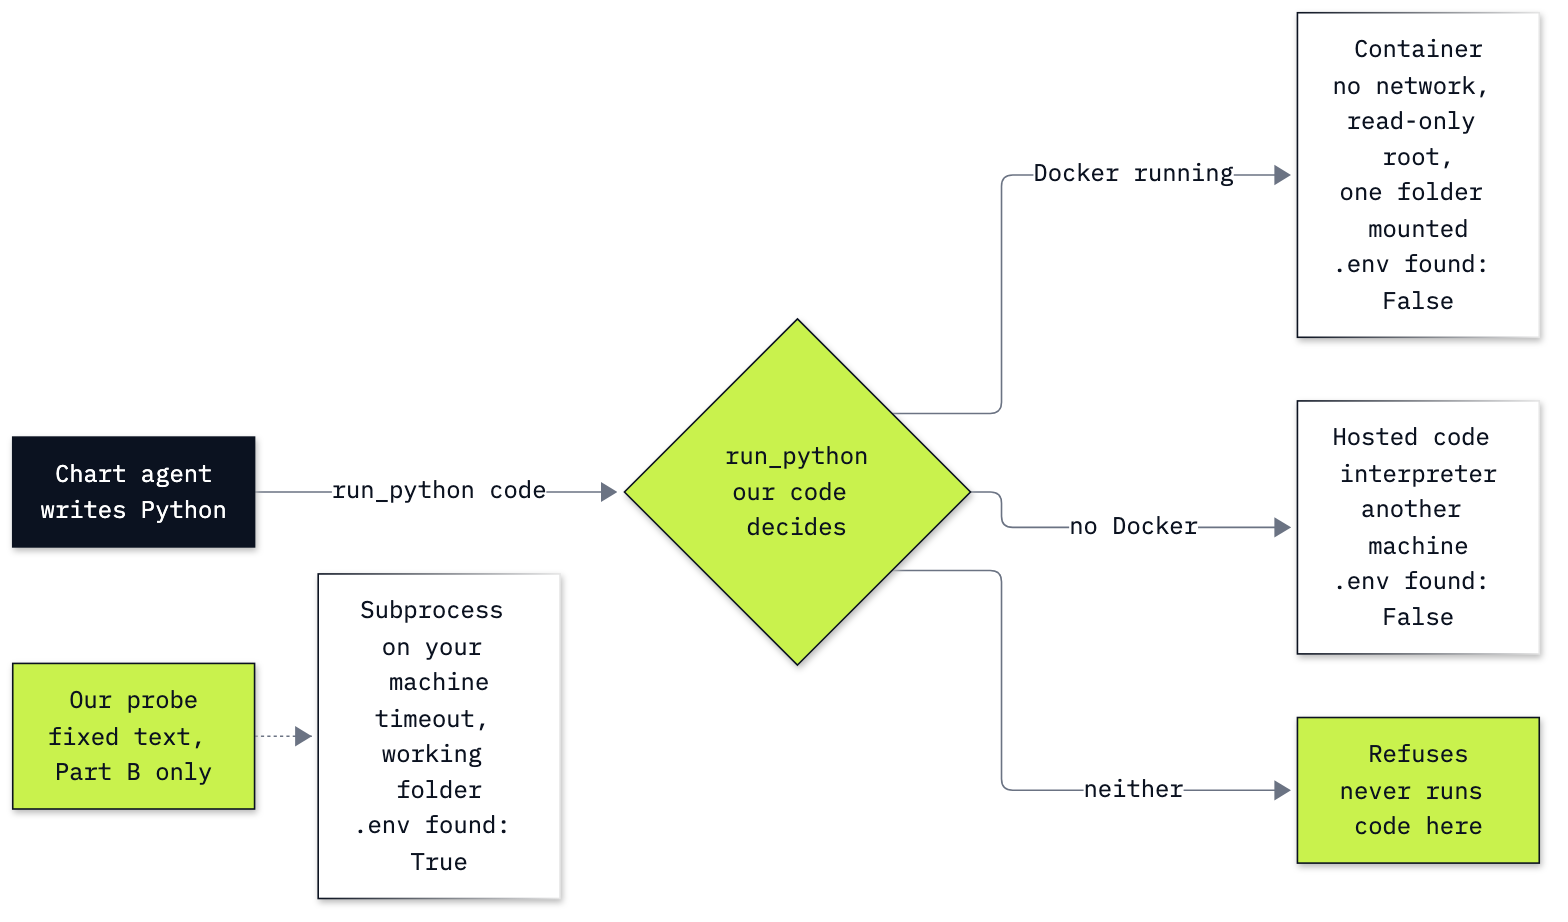

In [22]:
display(Image(filename=LAB / "resources" / "lab15_three_runners.png", width=760))

### The run_python tool

`run_python` tries the container first, when Docker is running; otherwise the hosted sandbox, unless you switch it
off with `USE_HOSTED = False`; otherwise it refuses. Its refusal is a sentence the model reads as the tool's result,
so the agent can tell the user why no chart was drawn.

⚠️ **There is no third branch that runs code here**: no subprocess, no `exec`. A sandbox that is missing is a reason
to stop, never a reason to run the code with fewer controls.

In [23]:
USE_HOSTED = True      # False: never pay for hosted sessions; run_python then needs Docker


def run_python(code):
    """The agent's tool: run code in a sandbox, or refuse. It never runs code on this machine."""
    if DOCKER_OK:
        return run_in_container(code)
    if USE_HOSTED:
        return run_hosted(code)
    return ("Not run: no sandbox is available (Docker is not running and the hosted runner is switched off). "
            "This tool never runs code on this machine.")


print("run_python sends code to:",
      "the container" if DOCKER_OK else "the hosted code interpreter" if USE_HOSTED else "nowhere: it refuses")

run_python sends code to: the container


In our run, `run_python` sends code to the container. To see the refusal, we pretend for one call that neither sandbox
is there, then put the two settings back. `saved = (DOCKER_OK, USE_HOSTED)` keeps both values in a tuple, and the last
line unpacks them into the two names again.

In [24]:
saved = (DOCKER_OK, USE_HOSTED)
DOCKER_OK, USE_HOSTED = False, False
print(run_python(PROBE))
DOCKER_OK, USE_HOSTED = saved

Not run: no sandbox is available (Docker is not running and the hosted runner is switched off). This tool never runs code on this machine.


The probe did not run anywhere; the tool returned its reason instead.

### The run_sql tool

The second tool runs one SQL query on the database we opened read-only in the setup cell, and returns at most 50 rows
as JSON text (`json.dumps` turns the list of tuples into text the model can read). A query that fails returns the
error as text, so the model can read it and try again. Two calls by hand: our yearly query, and a write the
connection must refuse.

In [25]:
def run_sql(query):
    """The agent's other tool: one query on the read-only database, at most 50 rows back as JSON."""
    try:
        return json.dumps(conn.execute(query).fetchmany(50))
    except sqlite3.Error as error:
        return f"SQLite error: {error}"


print(run_sql(YEARLY_SQL))
print(run_sql("DELETE FROM invoices WHERE InvoiceId = 1"))

[["2009", 449.46], ["2010", 481.45], ["2011", 469.58], ["2012", 477.53], ["2013", 450.58]]
SQLite error: attempt to write a readonly database


The five yearly rows as JSON, and `SQLite error: attempt to write a readonly database`: whatever SQL the model writes, the database cannot change.

### The schemas, the instructions and one call

Each tool is described to the model by a JSON schema: its name, what it does, and its arguments (one string each:
`query` and `code`). The description of `run_python` tells the model what the sandbox lacks: no database and no
network, so the numbers have to come from `run_sql`, and files go in the working folder. The system message is one
sentence, and the question asks for the chart we drew in Part A.

In [26]:
TOOLS = [
    {"type": "function", "function": {
        "name": "run_sql",
        "description": "Run one read-only SQLite query on the Chinook shop database and return up to 50 rows as JSON.",
        "parameters": {"type": "object", "properties": {"query": {"type": "string"}},
                       "required": ["query"], "additionalProperties": False}}},
    {"type": "function", "function": {
        "name": "run_python",
        "description": ("Run Python code with matplotlib in a sandbox and return what it printed. "
                        "The sandbox has no database and no network; save files in the working folder."),
        "parameters": {"type": "object", "properties": {"code": {"type": "string"}},
                       "required": ["code"], "additionalProperties": False}}},
]
SYSTEM = "You are the Chinook music shop's data assistant. Use run_sql to read the database and run_python to draw charts."
QUESTION = "Make a bar chart of the shop's revenue by year and save it as revenue_by_year.png."
print([tool["function"]["name"] for tool in TOOLS])

['run_sql', 'run_python']


Before the loop, one model call by hand, as in lab 03: we send the messages and the tools, and read what the model
asks for. Nothing runs in this cell.

In [27]:
messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": QUESTION}]
reply = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS,
                                       reasoning_effort=EFFORT or omit, max_completion_tokens=1500)
message = reply.choices[0].message
for call in message.tool_calls or []:
    print(call.function.name, call.function.arguments)

run_sql {"query":"SELECT strftime('%Y', InvoiceDate) AS year, ROUND(SUM(Total), 2) AS revenue FROM Invoice GROUP BY strftime('%Y', InvoiceDate) ORDER BY year"}


One call to `run_sql`, with a query the model wrote from a guess at the schema: the yearly totals from a table called `Invoice`. The shop's table is called `invoices`, so this query will fail, but nothing has run yet: this is only the request. The chart code comes later, once the model has numbers to draw.

### The loop

`ask_chart_agent` is the loop from lab 04 in one function. Each turn it sends the whole message list and the tools,
keeps the model's message, and if the model asked for tools, runs each one (`run_sql` or `run_python`), records the
step and sends the result back as a `tool` message with the call's id. When the model answers in text, the loop
returns that answer and the steps. `max_turns=8` caps it, so a model that keeps asking cannot run forever.
`agent_usage` keeps the usage of every call, for the cost at the end. `show_steps` prints each step in one line.

In [28]:
agent_usage = []      # the usage of every model call the agent makes


def ask_chart_agent(question, max_turns=8):
    """The loop from lab 04: call the model, run the tools it asks for, send the results back, until it answers."""
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    steps = []
    for turn in range(max_turns):
        reply = client.chat.completions.create(
            model=MODEL, messages=messages, tools=TOOLS,
            reasoning_effort=EFFORT or omit, max_completion_tokens=1500,
        )
        agent_usage.append(reply.usage)
        message = reply.choices[0].message
        messages.append(message)
        if not message.tool_calls:
            return message.content, steps
        for call in message.tool_calls:
            arguments = json.loads(call.function.arguments)
            if call.function.name == "run_sql":
                result = run_sql(arguments["query"])
            else:
                result = run_python(arguments["code"])
            steps.append((call.function.name, arguments, result))
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    return "Stopped: no answer within the turn limit.", steps

In [29]:
def show_steps(steps):
    for number, (name, arguments, result) in enumerate(steps, 1):
        if name == "run_sql":
            print(f"{number}. run_sql: {arguments['query'].strip()}")
        else:
            print(f"{number}. run_python: {len(arguments['code'].splitlines())} lines of code")
        print("   result:", result.strip().replace("\n", " / ")[:160])

Now the agent, on the question. We first delete any chart left from an earlier run (`unlink(missing_ok=True)` does
nothing if there is none), so the chart we look at afterwards is this run's.

In [30]:
for old in [OUTPUTS / "revenue_by_year.png", OUTPUTS / "hosted_chart_1.png"]:
    old.unlink(missing_ok=True)

answer, steps = ask_chart_agent(QUESTION)
show_steps(steps)
print("\nanswer:", answer)

1. run_sql: SELECT strftime('%Y', InvoiceDate) AS year, ROUND(SUM(Total), 2) AS revenue FROM Invoice GROUP BY strftime('%Y', InvoiceDate) ORDER BY year;
   result: SQLite error: no such table: Invoice
2. run_sql: SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;
   result: [["albums"], ["artists"], ["customers"], ["employees"], ["genres"], ["invoice_items"], ["invoices"], ["media_types"], ["playlist_track"], ["playlists"], ["sqlit
3. run_sql: SELECT strftime('%Y', invoice_date) AS year, ROUND(SUM(total), 2) AS revenue FROM invoices GROUP BY strftime('%Y', invoice_date) ORDER BY year;
   result: SQLite error: no such column: invoice_date
4. run_sql: PRAGMA table_info(invoices);
   result: [[0, "InvoiceId", "INTEGER", 1, null, 1], [1, "CustomerId", "INTEGER", 1, null, 0], [2, "InvoiceDate", "DATETIME", 1, null, 0], [3, "BillingAddress", "NVARCHAR(
5. run_sql: SELECT strftime('%Y', InvoiceDate) AS year, ROUND(SUM(Total), 2) AS revenue FROM invoices GROUP BY strftime('%Y', I

Six steps in our run, one per model call, and a seventh call for the answer. The first query named a table `Invoice` that does not exist, and the error came back as text. The model listed the tables, guessed a column `invoice_date` and got a second error, read the columns of `invoices` with `PRAGMA table_info`, and then wrote the right query, which returned the five rows of Part A. Only then did it call `run_python`, once, with 14 lines of code. The container printed *Saved revenue_by_year.png*, and the model answered. Errors returned as text are what let it recover: a tool that raised instead would have ended the run.

Here is the chart the agent's code drew in the sandbox. In the container it saved `revenue_by_year.png` into `/work`,
which is our `outputs/` folder; from the hosted sandbox it came back as an image that `run_hosted` saved as
`hosted_chart_1.png`.

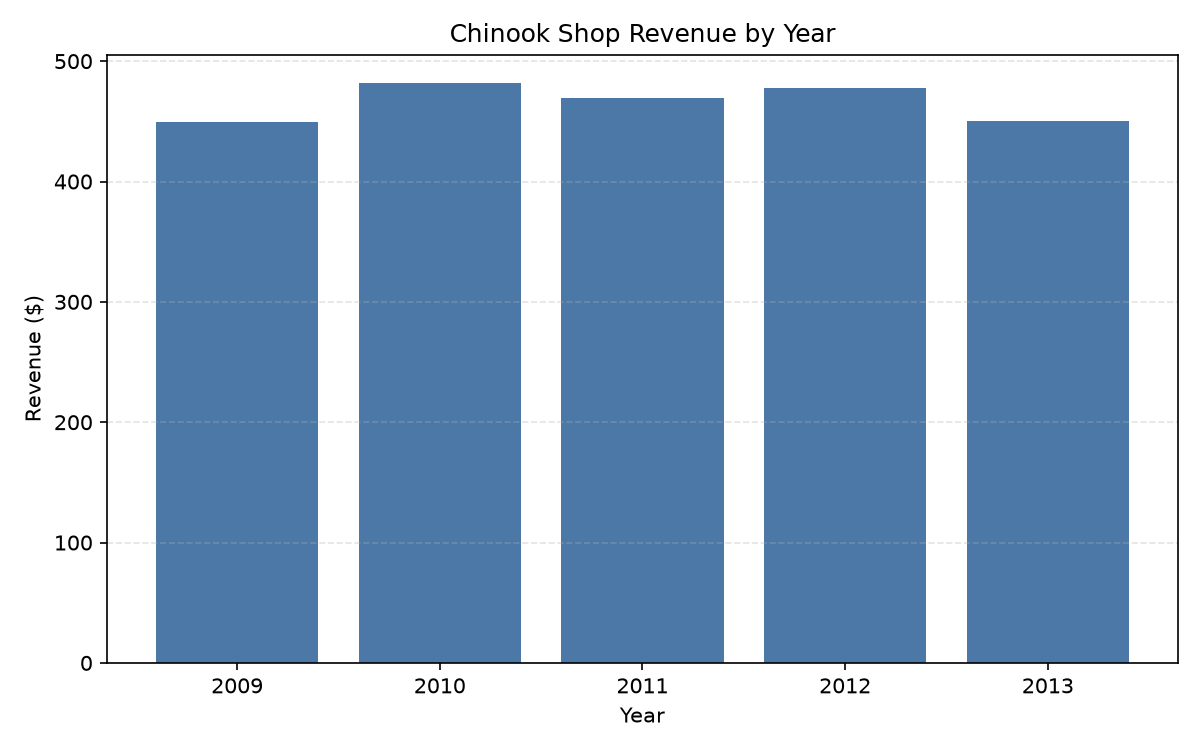

In [31]:
chart = OUTPUTS / "revenue_by_year.png" if DOCKER_OK else OUTPUTS / "hosted_chart_1.png"
display(Image(filename=chart, width=560))

Five bars, one per year, like our reference chart. The picture says nothing yet about where the heights came from:
the sandbox has no database. The code says it.

**Checkpoint E.** `run_python` sends code to the container (or the hosted sandbox without Docker) and refuses when
both are off; `run_sql` returns the five rows and `attempt to write a readonly database` for the delete; the agent
reads the database with `run_sql`, runs one piece of chart code in the sandbox and saves a chart with five bars
(ours took 5 `run_sql` calls, 2 of them errors it recovered from).

---

## Part F: Check the chart's numbers against the database

The sandbox could not read the database, yet the chart has the right shape. So where did its numbers come from? From
the only place they could: the model read them in `run_sql`'s result and typed them into its code. Here is the code
it sent to `run_python`:

In [32]:
code = [arguments["code"] for name, arguments, result in steps if name == "run_python"][-1]
print(code)

import matplotlib.pyplot as plt

years = ['2009', '2010', '2011', '2012', '2013']
revenue = [449.46, 481.45, 469.58, 477.53, 450.58]

plt.figure(figsize=(8, 5))
plt.bar(years, revenue, color='#4C78A8')
plt.title("Chinook Shop Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue ($)")
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.savefig('revenue_by_year.png', dpi=150)
print('Saved revenue_by_year.png')


Line 4 holds the answer: `revenue = [449.46, 481.45, 469.58, 477.53, 450.58]`. The model typed the five totals into its code as numbers, and they look like the database's. We check that in code rather than by eye. `re.findall(r"\d+\.\d+", code)` finds every decimal number
in the text: `\d+` is one or more digits and `\.` a literal dot. Each one becomes a `float`, rounded to cents, and we
look up each year's true revenue among them. The cell does this twice: year by year, so we can read it, and as
`totals_typed_in`, a function that returns only the count, for the runs that follow.

In [33]:
def totals_typed_in(code):
    """How many of the five true yearly totals appear as numbers typed into the code."""
    typed = {round(float(number), 2) for number in re.findall(r"\d+\.\d+", code)}
    return sum(revenue in typed for revenue in TRUTH.values())


typed = {round(float(number), 2) for number in re.findall(r"\d+\.\d+", code)}
for year, revenue in TRUTH.items():
    print(year, revenue, "| typed in the code:", revenue in typed)
print("totals typed in:", totals_typed_in(code), "of 5")

2009 449.46 | typed in the code: True
2010 481.45 | typed in the code: True
2011 469.58 | typed in the code: True
2012 477.53 | typed in the code: True
2013 450.58 | typed in the code: True
totals typed in: 5 of 5


All five are there, each equal to the database's value: `5 of 5`.

What this check establishes: in this run, every bar height in the code equals the database's value, so the chart is
right. What it leaves open: the next run. The numbers took a path through the model, and a model that copies five
numbers correctly can swap two digits in the sixth, or in a table of five hundred rows. A wrong number would draw a
wrong bar, with no error anywhere: the sandbox cannot notice, since it never sees the database.

One run is one sample. Two more runs of the same question, each checked the same way:

In [34]:
runs = [steps]
for _ in range(2):
    answer, more_steps = ask_chart_agent(QUESTION)
    runs.append(more_steps)

for number, run in enumerate(runs, 1):
    codes = [arguments["code"] for name, arguments, result in run if name == "run_python"]
    sql_calls = sum(name == "run_sql" for name, arguments, result in run)
    typed_in = totals_typed_in(codes[-1]) if codes else "no code"
    print(f"run {number}: {sql_calls} run_sql calls, {len(codes)} run_python call(s), totals typed in: {typed_in} of 5")

run 1: 5 run_sql calls, 1 run_python call(s), totals typed in: 5 of 5
run 2: 4 run_sql calls, 1 run_python call(s), totals typed in: 5 of 5
run 3: 3 run_sql calls, 1 run_python call(s), totals typed in: 5 of 5


In all three runs the agent wrote one piece of chart code with the five totals typed in, 5 of 5 every time. Only the number of `run_sql` calls changed (5, 4 and 3), with how many guesses at the schema failed first. The sandbox gave the code no other way to get the numbers.

**Lesson to Remember.** A sandbox decides what code can *reach*; it does not decide what the code *says*. Here the
data took a path through the model: the database, then the model's reading of `run_sql`'s result, then numbers typed
into code. The fix is to give the code the query result itself, so the model writes `revenue = [row[1] for row in
rows]` instead of typing numbers. That is the first challenge.

**Checkpoint F.** All five totals typed into the code, each equal to the database's value, in 3 of 3 runs.

---

## Part G: Choose an isolation level

We ran the same probe in three places. Each shares less with your machine than the one before:

| Where the probe ran | `.env there` | `key in environment` | `network` |
|---|---|---|---|
| a subprocess, with a timeout, a working folder and a trimmed environment | True | False | reachable |
| a container: no network, read-only root, one folder mounted | False | False | blocked |
| OpenAI's hosted code interpreter, another machine | False | False | blocked |

Practitioners name four levels of isolation. Each step up costs more and starts a little slower, so the rule is to
pick the weakest level you can defend for the code you run:

| Level | What it shares with your machine | Products | Use it for |
|---|---|---|---|
| A process | your files, network, user and keys | `subprocess`; the Agents SDK's Unix-local sandbox client | code you wrote and trust, like our probe |
| A container | the kernel only; you choose the folders and network it gets | Docker, Podman; the Agents SDK's Docker sandbox client | model-written code on your own machine, with the limits of Part C |
| A micro-VM | nothing but the hardware: it boots its own small kernel | Firecracker, Kata Containers; gVisor sits between (a kernel written in user space that stands in for yours) | code from many users, or code you have reason to distrust |
| A hosted sandbox | nothing: it is someone else's machine | OpenAI code interpreter, E2B, Modal, Daytona, Azure Container Apps dynamic sessions | when you cannot or should not run the box yourself |

**In production:**

- **Give the hosted tool to the agent itself.** We passed our agent's code through a second model call so one
  `run_python` could use either runner. With only the hosted sandbox, you would put `code_interpreter` in the agent's
  own Responses call beside your `run_sql` function: the model writes and runs its code there directly, and you read
  the code that ran from the `code_interpreter_call` items, as in Part D.
- **Frameworks ship the same choice.** The OpenAI Agents SDK's `SandboxAgent` gives an agent a workspace with shell
  and file tools, and you pick where it runs: a Unix-local client, Docker, or a hosted provider (E2B, Modal, Daytona,
  Vercel, Cloudflare, Blaxel). Its documentation says the local client adds no confinement on Linux, and points
  untrusted commands to Docker or a hosted sandbox: the lesson of Part B, in the framework's own words.
- **The container limits are a start.** A real deployment adds a time limit per session, a size limit on the files
  code can write, and logs of every run; for untrusted code from many users, it moves to a micro-VM or a hosted
  sandbox.

The diagram in Part E is the design this lab used: the model writes, our code decides, and code runs only behind a
wall we tested.

**Checkpoint G.** For each runner, the three answers in the first table; and for each level, one product and one
case you would use it for.

### What this notebook cost

Every model call the agent made, and every hosted run, priced from `models.env` and the session price above:

In [35]:
agent_usd = sum(price(u.prompt_tokens, u.prompt_tokens_details.cached_tokens or 0,
                      getattr(u.prompt_tokens_details, "cache_write_tokens", 0) or 0, u.completion_tokens)
                for u in agent_usage)
hosted = [response.usage] + [run["usage"] for run in hosted_runs]
hosted_usd = sum(price(u.input_tokens, u.input_tokens_details.cached_tokens or 0,
                       u.input_tokens_details.cache_write_tokens or 0, u.output_tokens) for u in hosted)
sessions_usd = len(hosted) * CONTAINER_SESSION_USD
print(f"agent: {len(agent_usage)} model calls, ${agent_usd:.4f}")
print(f"hosted sandbox: {len(hosted)} runs, tokens ${hosted_usd:.4f} + sessions ${sessions_usd:.2f}")
print(f"total: about ${agent_usd + hosted_usd + sessions_usd:.2f}")

agent: 18 model calls, $0.0015
hosted sandbox: 2 runs, tokens $0.0002 + sessions $0.06
total: about $0.06


The agent's 18 model calls, for three runs, cost less than a fifth of a cent. The two hosted runs cost $0.06, almost all of it the two container sessions. The agent's code ran in the local container, which costs nothing beyond your machine; without Docker each of its three `run_python` calls would have been one more hosted session.

## What you can do now

- Test a runner with a probe of your own, and say which of its controls stopped which line: a subprocess's timeout,
  working folder and trimmed environment stop none of `.env`, the network or the disk (Part B).
- Build an image with a non-root user and run code in a container with no network, a read-only root, memory, CPU and
  process limits and one mounted folder, and explain each flag (Part C).
- Run code in OpenAI's hosted code interpreter with the Responses API, read the `code_interpreter_call` item, check
  that the code that ran is the code you sent, and price the run with its container session (Part D).
- Give an agent a `run_python` tool that sends code only to a sandbox and refuses when there is none (Part E).
- Check a chart's numbers against the database in code, and say why numbers typed by the model are a risk even when
  they match (Part F).
- Choose an isolation level for a piece of code, and name a product for it (Part G).

## Challenge

Start from the setup cells, Part C's container (or Part D's hosted runner) and Part E's tools and loop.

1. **Keep the totals out of the model's code.** Change `run_sql` so it also keeps the rows of its last query in a
   variable, `last_rows` (write `global last_rows` as the function's first line, so it replaces the variable outside
   the function instead of making a new one inside it). Change `run_python` so it puts one line before the model's code, `rows = ` followed by those
   rows as JSON (`json.dumps(last_rows)`), and say in the tool's description that `rows` holds the last query's
   result and that the code must use it and never type numbers in. Run the agent three times and check each code with
   `totals_typed_in`. *Expected:* `0 of 5` in every run, code that builds its lists from `rows`, and a chart with the
   same five bars as the reference chart. The numbers now go from the database to the chart through our code only.
2. **Test the container's limits with two probes of your own** (needs Docker). Send `while True: pass` and a program
   that builds a 300 MB bytes object (`b"x" * (300 * 1024 * 1024)`) through `run_in_container`. *Expected:* nothing
   printed and exit code 124 for the first (the `timeout` program stopped it after 20 seconds), and exit code 137 for
   the second (128 + 9: the kernel killed it with signal 9 at the 256 MB memory limit). Say which flag stopped each.

A worked solution, run with its outputs, is in `solved/15_code_execution_solution.ipynb`.

## Troubleshooting

Each message below was triggered on purpose and copied from a run.

| What you see | Why | Fix |
|---|---|---|
| `docker server: failed to connect to the docker API at unix:///...; check if the path is correct and if the daemon is running` | Docker is installed but not running (or `DOCKER_HOST` points to a socket that does not exist) | start Docker Desktop (Linux: `sudo systemctl start docker`) and run Part C's first cell again; or carry on: `run_python` uses the hosted sandbox |
| `ModuleNotFoundError: No module named 'pandas'` in a `run_python` result | the image holds only matplotlib and numpy; the agent wrote code for a library that is not there | the agent usually rewrites the code without it; to allow a library, add it to the Dockerfile's `pip install` line and run the build cell again |
| `finished with exit code 137, printed nothing` | the code used more than the 256 MB memory limit, and the kernel stopped it | expected for a memory probe; for real work, raise `--memory` and `--memory-swap` together |
| `finished with exit code 124, printed nothing` | the code ran longer than 20 seconds, and `timeout` stopped it | expected for an endless loop; for slow real work, raise the `timeout 20` in `run_in_container` |
| `Warning: the hosted runner changed the code before running it.` | the model retyped the code with a change before running it in the hosted sandbox | read the difference in `hosted_runs[-1]`; run it again, or use the container |

## Resources

- [OpenAI: code interpreter](https://developers.openai.com/api/docs/guides/tools-code-interpreter): the tool, its
  containers (auto or explicit, memory sizes, the 20-minute expiry) and the files and images it returns
- [OpenAI: pricing, built-in tools](https://developers.openai.com/api/docs/pricing): the container session prices
- [Docker: `docker container run`](https://docs.docker.com/reference/cli/docker/container/run/): every flag used in
  Part C
- [Docker: resource constraints](https://docs.docker.com/engine/containers/resource_constraints/): `--memory`,
  `--memory-swap`, `--cpus`
- [Dockerfile reference: `USER`](https://docs.docker.com/reference/dockerfile/#user): running an image's commands as
  another user
- [Python: `subprocess`](https://docs.python.org/3/library/subprocess.html): `run`, `cwd`, `env`, `timeout` and
  `TimeoutExpired`
- [OpenAI Agents SDK: sandbox agents](https://openai.github.io/openai-agents-python/sandbox_agents/) and
  [sandbox clients](https://openai.github.io/openai-agents-python/sandbox/clients/): `SandboxAgent`, the Unix-local
  limits, Docker and the hosted providers
- [gVisor](https://gvisor.dev/docs/) and [Firecracker](https://firecracker-microvm.github.io/): the two stronger
  walls between a container and a full virtual machine
- [Azure Container Apps: dynamic sessions](https://learn.microsoft.com/en-us/azure/container-apps/sessions): a hosted
  sandbox on Azure